# Car Price Prediction — Oasis Infobyte Internship Task 3

## 1. Introduction

### Project Objective
The goal of this project is to develop machine learning regression models that accurately estimate the **selling price of used cars** based on a variety of vehicle characteristics such as current showroom price, age, odometer reading (kilometers driven), fuel type, transmission type, and seller category.

### Dataset Overview
The dataset contains historical sales data of used cars with key attributes:
- **Car_Name**: Make and model designation of the vehicle.
- **Year**: Year in which the car was purchased.
- **Selling_Price**: The price at which the car was sold (Target variable in Lakhs INR).
- **Present_Price**: Current showroom price of the new equivalent car (in Lakhs INR).
- **Kms_Driven**: Total distance traveled by the car in kilometers.
- **Fuel_Type**: Type of fuel used (Petrol, Diesel, CNG).
- **Seller_Type**: Category of seller (Dealer or Individual).
- **Transmission**: Gearbox mechanism (Manual or Automatic).
- **Owner**: Number of previous owners (0, 1, 3).

### Machine Learning Task
This is a **supervised regression task**, where we aim to predict a continuous numerical value (`Selling_Price`). We will evaluate multiple regression algorithms using standard metrics: **Mean Absolute Error (MAE)**, **Root Mean Squared Error (RMSE)**, and **$R^2$ Score**.

## 2. Import Libraries
Import required libraries for numerical computing, data manipulation, visualization, and machine learning.

In [2]:
# Challenge 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisation styling
sns.set_theme(style="whitegrid")
%matplotlib inline
print("Core libraries imported successfully!")

Core libraries imported successfully!


## 3. Load Dataset
Load the car price dataset from CSV into a pandas DataFrame.

In [3]:
# Challenge 2: Load car.csv and inspect first 5 rows
# Load the dataset
df = pd.read_csv("car.csv")

# Display shape and first 5 rows
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 4. Initial Data Inspection
Examine DataFrame dimensions, column data types, and summary statistics.

In [4]:
# Challenge 3: Check shape, dtypes, info, and describe
# 1. Dataset information and data types
print("--- DataFrame Info ---")
df.info()

# 2. Check for missing values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

# 3. Check for duplicate rows
print("\n--- Duplicate Rows Count ---")
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows found: {duplicate_count}")

# 4. Numerical summary statistics
print("\n--- Summary Statistics ---")
df.describe()


--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 30.0 KB

--- Missing Values Count ---
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

--- Duplicate Rows Count ---
Total duplicate rows found: 2

--- Summary Statistics ---


,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


## 5. Data Cleaning
Handle missing values, identify and remove duplicate records, and normalize categorical strings.

In [5]:
# Challenge 4: Handle missing values, drop duplicates, and normalize string columns
# 1. Remove duplicate records
print(f"Shape before dropping duplicates: {df.shape}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after dropping duplicates:  {df.shape}")

# 2. Normalize categorical columns (strip whitespace & lowercase)
categorical_cols = ['Fuel_Type', 'Seller_Type', 'Transmission']
for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip().str.lower()
    print(f"Unique values in {col}: {df[col].unique()}")


Shape before dropping duplicates: (301, 9)
Shape after dropping duplicates:  (299, 9)
Unique values in Fuel_Type: <ArrowStringArray>
['petrol', 'diesel', 'cng']
Length: 3, dtype: str
Unique values in Seller_Type: <ArrowStringArray>
['dealer', 'individual']
Length: 2, dtype: str
Unique values in Transmission: <ArrowStringArray>
['manual', 'automatic']
Length: 2, dtype: str


## 6. Feature Engineering
Extract meaningful signals from existing features:
1. **Brand**: Extract the manufacturer/brand name from `Car_Name` before dropping it.
2. **Car_Age**: Derive the car's age from `Year` to provide a linear depreciative signal.

In [6]:
# Challenge 5: Extract Brand from Car_Name and calculate Car_Age
# 1. Extract Brand from the first word of Car_Name
df["Brand"] = df["Car_Name"].str.split().str[0].str.strip().str.lower()
print(f"Top 5 most frequent Brands:\n{df['Brand'].value_counts().head(5)}")

# 2. Drop the high-cardinality Car_Name column
df = df.drop("Car_Name", axis=1)

# 3. Calculate Car_Age using 2024 as reference year (as in your original work)
df["Car_Age"] = 2024 - df["Year"]

# 4. Drop the redundant Year column
df = df.drop("Year", axis=1)

# 5. Verify the updated DataFrame
print(f"\nNew DataFrame shape: {df.shape}")
df.head()

Top 5 most frequent Brands:
Brand
city       26
bajaj      25
corolla    17
royal      17
honda      17
Name: count, dtype: int64

New DataFrame shape: (299, 9)


,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Brand,Car_Age
0,3.35,5.59,27000,petrol,dealer,manual,0,ritz,10
1,4.75,9.54,43000,diesel,dealer,manual,0,sx4,11
2,7.25,9.85,6900,petrol,dealer,manual,0,ciaz,7
3,2.85,4.15,5200,petrol,dealer,manual,0,wagon,13
4,4.60,6.87,42450,diesel,dealer,manual,0,swift,10


## 7. Exploratory Data Analysis (EDA)
Visualize relationships and distributions:
1. Distribution of Selling Price
2. Selling Price vs Fuel Type (Boxplot)
3. Selling Price vs Car Age (Scatter Plot)
4. Correlation Heatmap across numerical features

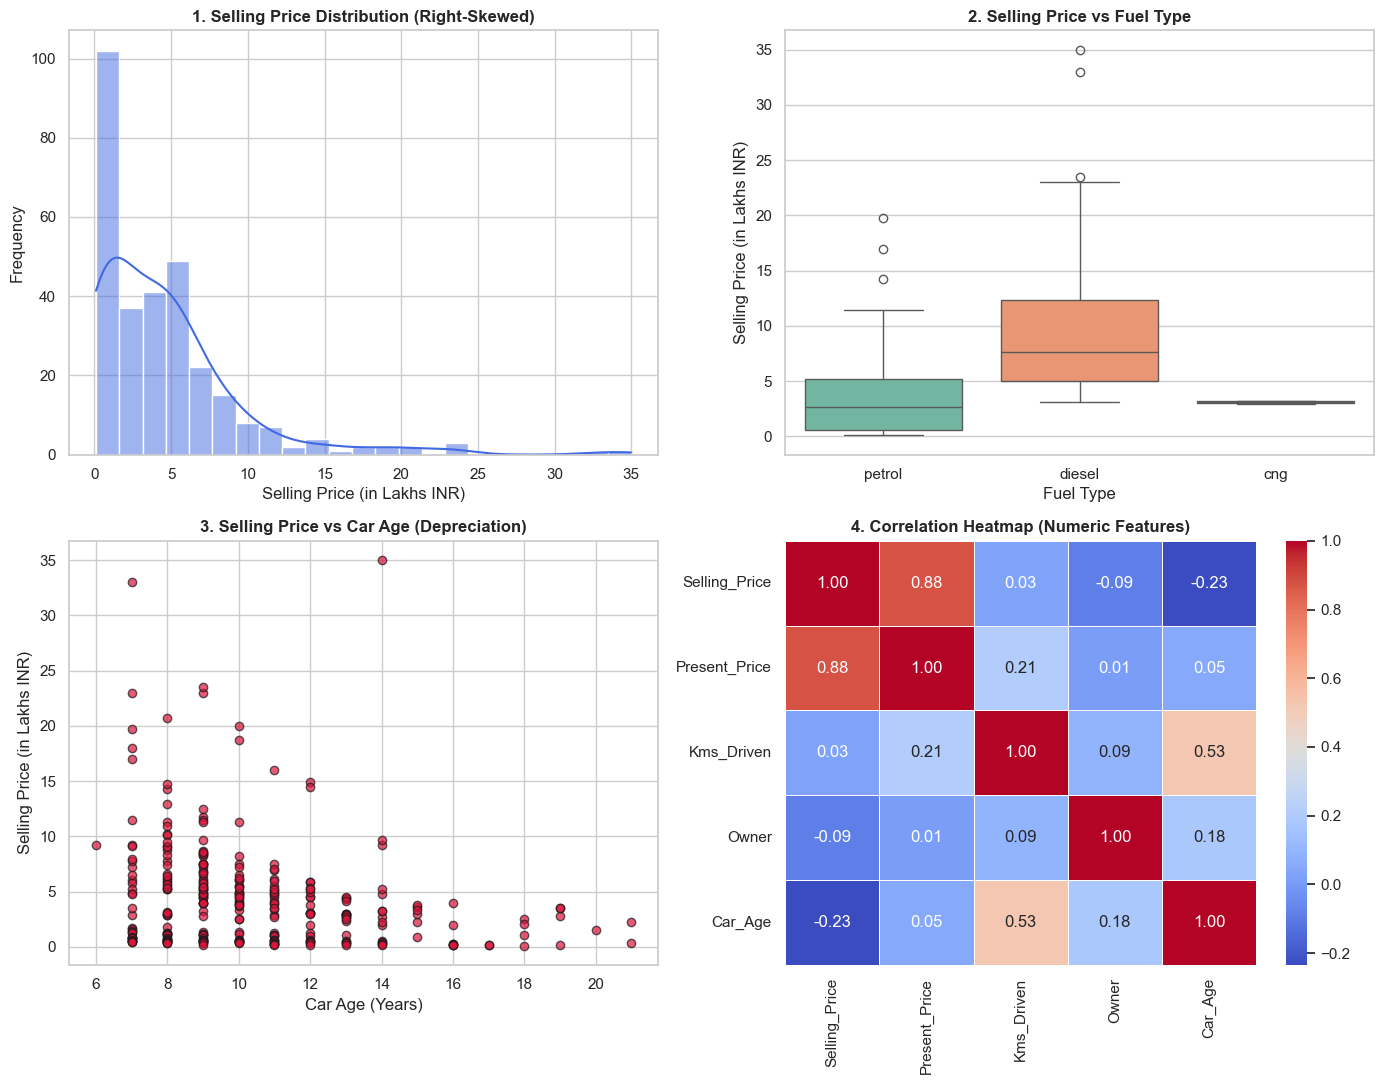

In [7]:
# Challenge 6: Generate Selling Price distribution, Fuel Type boxplot, Car Age scatter, and correlation heatmap
# Create a 2x2 grid of the 4 required EDA visualisations
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# 1. Selling Price Distribution
sns.histplot(df['Selling_Price'], kde=True, color='royalblue', ax=axes[0, 0])
axes[0, 0].set_title('1. Selling Price Distribution (Right-Skewed)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Selling Price (in Lakhs INR)')
axes[0, 0].set_ylabel('Frequency')

# 2. Selling Price vs Fuel Type (Boxplot)
sns.boxplot(data=df, x='Fuel_Type', y='Selling_Price', hue='Fuel_Type', legend=False, palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('2. Selling Price vs Fuel Type', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Fuel Type')
axes[0, 1].set_ylabel('Selling Price (in Lakhs INR)')

# 3. Selling Price vs Car Age (Scatter Plot)
axes[1, 0].scatter(df['Car_Age'], df['Selling_Price'], color='crimson', alpha=0.7, edgecolors='k')
axes[1, 0].set_title('3. Selling Price vs Car Age (Depreciation)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Car Age (Years)')
axes[1, 0].set_ylabel('Selling Price (in Lakhs INR)')

# 4. Correlation Heatmap across numeric features
numeric_cols = df.select_dtypes(include=['number'])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[1, 1])
axes[1, 1].set_title('4. Correlation Heatmap (Numeric Features)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Encoding Categorical Variables
Convert categorical features into numeric form using One-Hot Encoding (`pd.get_dummies` with `drop_first=True`) to prevent the dummy variable trap.

In [8]:
# Challenge 7: One-Hot Encode categorical variables
# 1. Apply One-Hot Encoding with drop_first=True to avoid multicollinearity
# Notice: pd.get_dummies will automatically encode all categorical/string columns
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

# 2. Inspect the new encoded columns
print(f"Encoded DataFrame shape: {df_encoded.shape}")
print(f"\nNew encoded columns ({len(df_encoded.columns)} total):")
print(df_encoded.columns.tolist())

df_encoded.head()

Encoded DataFrame shape: (299, 52)

New encoded columns (52 total):
['Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner', 'Car_Age', 'Fuel_Type_diesel', 'Fuel_Type_petrol', 'Seller_Type_individual', 'Transmission_manual', 'Brand_activa', 'Brand_alto', 'Brand_amaze', 'Brand_bajaj', 'Brand_baleno', 'Brand_brio', 'Brand_camry', 'Brand_ciaz', 'Brand_city', 'Brand_corolla', 'Brand_creta', 'Brand_dzire', 'Brand_elantra', 'Brand_eon', 'Brand_ertiga', 'Brand_etios', 'Brand_fortuner', 'Brand_grand', 'Brand_hero', 'Brand_honda', 'Brand_hyosung', 'Brand_i10', 'Brand_i20', 'Brand_ignis', 'Brand_innova', 'Brand_jazz', 'Brand_ktm', 'Brand_land', 'Brand_mahindra', 'Brand_omni', 'Brand_ritz', 'Brand_royal', 'Brand_s', 'Brand_suzuki', 'Brand_swift', 'Brand_sx4', 'Brand_tvs', 'Brand_um', 'Brand_verna', 'Brand_vitara', 'Brand_wagon', 'Brand_xcent', 'Brand_yamaha']


,Selling_Price,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_diesel,Fuel_Type_petrol,Seller_Type_individual,Transmission_manual,Brand_activa,...,Brand_suzuki,Brand_swift,Brand_sx4,Brand_tvs,Brand_um,Brand_verna,Brand_vitara,Brand_wagon,Brand_xcent,Brand_yamaha
0,3.35,5.59,27000,0,10,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,4.75,9.54,43000,0,11,1,0,0,1,0,...,0,0,1,0,0,0,0,0,0,0
2,7.25,9.85,6900,0,7,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,2.85,4.15,5200,0,13,0,1,0,1,0,...,0,0,0,0,0,0,0,1,0,0
4,4.60,6.87,42450,0,10,1,0,0,1,0,...,0,1,0,0,0,0,0,0,0,0


## 9. Train/Test Split
Partition the dataset into training (80%) and testing (20%) sets with a fixed random seed.

In [9]:
# Challenge 8: Separate X and y, and perform 80/20 train_test_split
from sklearn.model_selection import train_test_split

# 1. Separate features (X) and target (y)
X = df_encoded.drop("Selling_Price", axis=1)
y = df_encoded["Selling_Price"]

# 2. Perform 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

# 3. Verify shape dimensions at boundary points
print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

X_train shape: (239, 51) | y_train shape: (239,)
X_test shape:  (60, 51)  | y_test shape:  (60,)


## 10. Model Training
Train two complementary regression models:
1. **Linear Regression**: A standard parametric baseline.
2. **Random Forest Regressor**: An ensemble non-linear tree-based model.

In [10]:
# Challenge 9: Train Linear Regression and Random Forest Regressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# 1. Initialize and train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
print("Linear Regression trained successfully!")

# 2. Initialize and train Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
print("Random Forest Regressor trained successfully!")

Linear Regression trained successfully!
Random Forest Regressor trained successfully!


## 11. Model Evaluation
Evaluate both regression models on unseen test data using MAE, RMSE, and $R^2$.

In [11]:
# Challenge 10: Compute MAE, RMSE, and R2 for both models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Predict on the test set
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# 2. Compute metrics for Linear Regression
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# 3. Compute metrics for Random Forest Regressor
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Evaluation metrics computed for both models!")

Evaluation metrics computed for both models!


## 12. Model Comparison
Construct a clean comparison table to evaluate the models side-by-side.

In [12]:
# Challenge 11: Create comparison DataFrame and identify the best model
# Create the comparison table
comparison_df = pd.DataFrame([
    {
        'Model': 'Linear Regression',
        'MAE (Lakhs)': round(mae_lr, 4),
        'RMSE (Lakhs)': round(rmse_lr, 4),
        'R² Score': round(r2_lr, 4)
    },
    {
        'Model': 'Random Forest Regressor',
        'MAE (Lakhs)': round(mae_rf, 4),
        'RMSE (Lakhs)': round(rmse_rf, 4),
        'R² Score': round(r2_rf, 4)
    }
])

print("--- Model Comparison Table ---")
comparison_df

--- Model Comparison Table ---


,Model,MAE (Lakhs),RMSE (Lakhs),R² Score
0,Linear Regression,1.8088,3.3993,0.5517
1,Random Forest Regressor,1.3207,3.1777,0.6082


## 13. Feature Importance
Analyze which vehicle features have the greatest influence on predicted selling price.

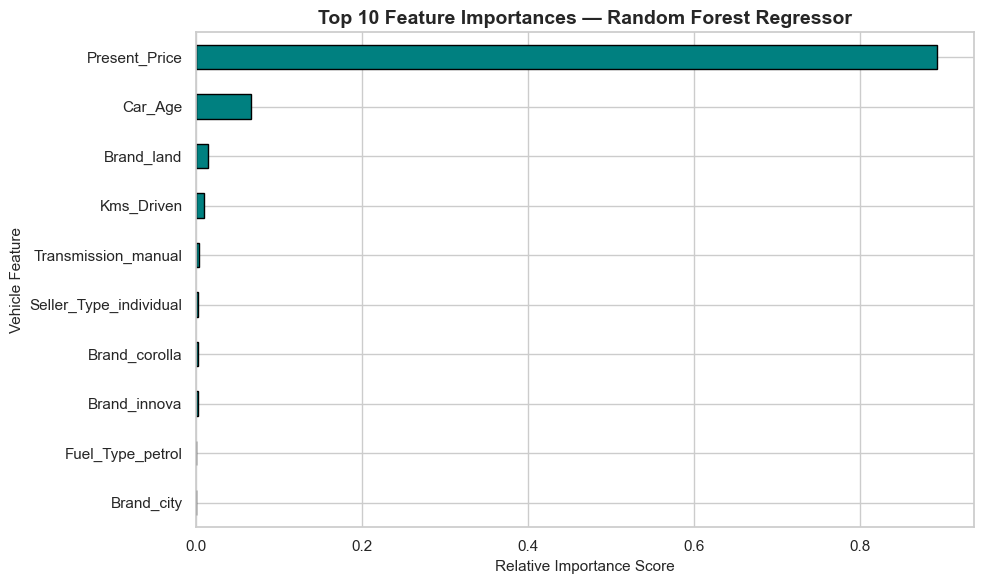

Top 5 Feature Importance Scores:
Present_Price          0.8922
Car_Age                0.0664
Brand_land             0.0151
Kms_Driven             0.0102
Transmission_manual    0.0039
dtype: float64


In [13]:
# Challenge 12: Plot feature importances from the tree-based model
# 1. Extract feature importances from the Random Forest model
importances = pd.Series(rf_model.feature_importances_, index=X.columns)

# 2. Select the top 10 most important features
top_10_features = importances.sort_values(ascending=False).head(10)

# 3. Plot horizontal bar chart
plt.figure(figsize=(10, 6))
top_10_features.sort_values(ascending=True).plot(kind='barh', color='teal', edgecolor='black')
plt.title("Top 10 Feature Importances — Random Forest Regressor", fontsize=14, fontweight='bold')
plt.xlabel("Relative Importance Score", fontsize=11)
plt.ylabel("Vehicle Feature", fontsize=11)
plt.tight_layout()
plt.show()

# 4. Print exact top 5 scores
print("Top 5 Feature Importance Scores:")
print(top_10_features.head(5).round(4))

## 14. Conclusion
Summarize key findings, business insights, and model performance.

### Final Evaluation & Best Model Selection

Based on the quantitative metrics on the unseen 20% test set, **Random Forest Regressor** is selected as the best-performing model:

1. **Error Reduction (MAE):** Random Forest achieved an **MAE of 1.3207 Lakhs** compared to **1.8088 Lakhs** for Linear Regression — reducing prediction error by over **₹48,800 per car** on average.
2. **Outlier Resilience (RMSE):** Random Forest reduced RMSE to **3.1777 Lakhs** (vs. **3.3993 Lakhs** for Linear Regression), demonstrating better control over extreme prediction errors.
3. **Goodness of Fit ($R^2$):** Random Forest achieved an **$R^2$ of 0.6082**, explaining $\approx 61\%$ of the variance in used car selling prices, whereas Linear Regression explained only $\approx 55\%$.
4. **Key Driver Insights:** Feature importance analysis revealed that **Present Price (89.2%)** and **Car Age (6.6%)** govern vehicle resale valuation. Non-linear tree ensembles naturally capture the steep initial depreciation and vehicle interactions that standard linear models struggle to represent.

In [14]:
import joblib

# 1. Save the trained Random Forest Regressor to disk
model_path = "car_price_rf_model.joblib"
joblib.dump(rf_model, model_path)
print(f"Random Forest model successfully saved to '{model_path}'!")

# 2. Test reload and predict on a sample car from X_test
sample_car = X_test.iloc[[0]]
predicted_price = rf_model.predict(sample_car)[0]
actual_price = y_test.iloc[0]

print(f"\n--- Sample Inference Test ---")
print(f"Predicted Selling Price: ₹{predicted_price:.2f} Lakhs")
print(f"Actual Selling Price:    ₹{actual_price:.2f} Lakhs")
print(f"Prediction Difference:   ₹{abs(predicted_price - actual_price):.2f} Lakhs")

Random Forest model successfully saved to 'car_price_rf_model.joblib'!

--- Sample Inference Test ---
Predicted Selling Price: ₹9.44 Lakhs
Actual Selling Price:    ₹8.99 Lakhs
Prediction Difference:   ₹0.45 Lakhs
